# Logging & Configuration

`print()` is fine in a notebook. In a program that runs on a server, you need **logging**: messages with a time, a severity level and a source, which go to the console, files or a log platform. You also need **configuration** that changes between laptop, test and production without code changes.

**After this lesson you can:**

1. Use the `logging` module with levels, loggers, handlers and formatters.
2. Log exceptions with their tracebacks.
3. Write structured (JSON) logs.
4. Load typed, validated configuration from environment variables.

## 1. Levels and Loggers

| Level | Value | Use for |
| :--- | :-: | :--- |
| `DEBUG` | 10 | details for developers |
| `INFO` | 20 | normal events: "job started", "1,200 rows loaded" |
| `WARNING` | 30 | something unexpected, but the program continues |
| `ERROR` | 40 | an operation failed |
| `CRITICAL` | 50 | the program cannot continue |

A logger has a name, usually `__name__` of the module. Names form a hierarchy (`shop`, `shop.db`, `shop.api`), so you can set the level for a whole package.

In [1]:
import io
import json
import logging
import sys

for h in logging.root.handlers[:]:                 # start from a clean state in the notebook
    logging.root.removeHandler(h)

logging.basicConfig(level=logging.INFO, stream=sys.stdout,
                    format="%(asctime)s | %(levelname)-8s | %(name)s | %(message)s", datefmt="%H:%M:%S")
log = logging.getLogger("shop.orders")

log.debug("not shown: the level is INFO")
log.info("processing %d orders", 3)                 # use %-style arguments, not f-strings
log.warning("order %s has no country, using default", 17)
logging.getLogger("shop.db").setLevel(logging.ERROR)
logging.getLogger("shop.db").warning("not shown: shop.db only reports errors")
logging.getLogger("shop.db").error("connection lost")

16:17:11 | INFO     | shop.orders | processing 3 orders


16:17:11 | WARNING  | shop.orders | order 17 has no country, using default


16:17:11 | ERROR    | shop.db | connection lost


Pass values as arguments (`log.info("%d orders", n)`) instead of f-strings. Logging then builds the message only if the level is enabled, and log platforms can group messages with the same template.

## 2. Log Exceptions

`log.exception()` inside an `except` block logs the message at level `ERROR` together with the full traceback.

In [2]:
def parse_amount(text: str) -> float:
    try:
        return float(text)
    except ValueError:
        log.exception("cannot parse amount %r", text)
        return 0.0

parse_amount("12,50")

16:17:11 | ERROR    | shop.orders | cannot parse amount '12,50'
Traceback (most recent call last):
  File "/tmp/ipykernel_41140/3851325043.py", line 3, in parse_amount
    return float(text)
           ^^^^^^^^^^^
ValueError: could not convert string to float: '12,50'


0.0

## 3. Handlers and Structured (JSON) Logs

A **handler** sends records to a destination (console, file, network). A **formatter** turns a record into text. Log platforms such as Grafana Loki or Elasticsearch (M34) search **JSON** logs much better than plain text, because every field is a key.

In [3]:
class JsonFormatter(logging.Formatter):
    def format(self, record: logging.LogRecord) -> str:
        data = {"time": self.formatTime(record, "%Y-%m-%dT%H:%M:%S"), "level": record.levelname,
                "logger": record.name, "message": record.getMessage()}
        data.update(getattr(record, "context", {}))      # extra fields
        if record.exc_info:
            data["error"] = self.formatException(record.exc_info).splitlines()[-1]
        return json.dumps(data)

buffer = io.StringIO()
json_handler = logging.StreamHandler(buffer)
json_handler.setFormatter(JsonFormatter())
pipeline_log = logging.getLogger("pipeline")
pipeline_log.addHandler(json_handler)
pipeline_log.propagate = False                        # do not also print through the root handler
pipeline_log.setLevel(logging.DEBUG)

pipeline_log.info("batch loaded", extra={"context": {"batch_id": 42, "rows": 1200}})
try:
    1 / 0
except ZeroDivisionError:
    pipeline_log.error("metric failed", exc_info=True, extra={"context": {"metric": "ratio"}})
print(buffer.getvalue())

{"time": "2026-11-16T16:17:11", "level": "INFO", "logger": "pipeline", "message": "batch loaded", "batch_id": 42, "rows": 1200}
{"time": "2026-11-16T16:17:11", "level": "ERROR", "logger": "pipeline", "message": "metric failed", "metric": "ratio", "error": "ZeroDivisionError: division by zero"}



## 4. Log Levels Over a Pipeline Run

The cell runs a small simulated pipeline (synthetic events) that logs through the JSON handler. Then it parses the logs back and counts the records per step and level, the way a log platform would.

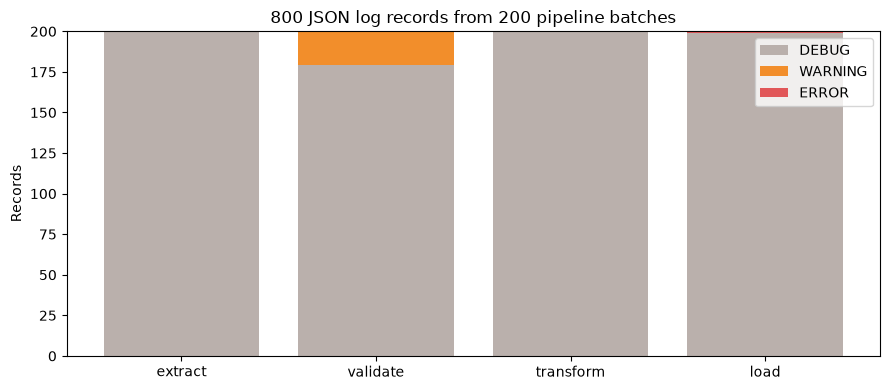

{'DEBUG': 778, 'WARNING': 21, 'ERROR': 1}


In [4]:
import random
from collections import Counter

import matplotlib.pyplot as plt

random.seed(11)
buffer.seek(0); buffer.truncate()
steps = ["extract", "validate", "transform", "load"]
for batch in range(200):
    for step in steps:
        r = random.random()
        ctx = {"context": {"step": step, "batch": batch}}
        if step == "validate" and r < 0.08:
            pipeline_log.warning("rows with missing values dropped", extra=ctx)
        elif step == "load" and r < 0.02:
            pipeline_log.error("load failed, will retry", extra=ctx)
        else:
            pipeline_log.debug("step ok", extra=ctx)

records = [json.loads(line) for line in buffer.getvalue().splitlines()]
counts = Counter((r["step"], r["level"]) for r in records)
levels = ["DEBUG", "WARNING", "ERROR"]
colors = {"DEBUG": "#BAB0AC", "WARNING": "#F28E2B", "ERROR": "#E15759"}

fig, ax = plt.subplots(figsize=(9, 4))
bottom = [0] * len(steps)
for level in levels:
    vals = [counts[(s, level)] for s in steps]
    ax.bar(steps, vals, bottom=bottom, color=colors[level], label=level)
    bottom = [b + v for b, v in zip(bottom, vals)]
ax.set(title=f"{len(records)} JSON log records from 200 pipeline batches", ylabel="Records")
ax.legend()
plt.tight_layout()
plt.show()
print({lvl: sum(v for (s, l), v in counts.items() if l == lvl) for lvl in levels})

## 5. Configuration from Environment Variables

The **twelve-factor app** method stores configuration in **environment variables**. The same code then runs on a laptop, in CI and in production, with different settings. Read the variables once, into a typed and validated object. Pydantic (M01) checks the types and fails early with a clear message.

In [5]:
import os

from pydantic import BaseModel, Field, ValidationError

class Settings(BaseModel):
    app_env: str = Field(default="dev", pattern="^(dev|test|prod)$")
    database_url: str = "sqlite:///local.db"
    log_level: str = Field(default="INFO", pattern="^(DEBUG|INFO|WARNING|ERROR)$")
    max_workers: int = Field(default=4, ge=1, le=64)
    api_key: str | None = None

    @classmethod
    def from_env(cls, prefix: str = "SHOP_") -> "Settings":
        values = {k[len(prefix):].lower(): v for k, v in os.environ.items() if k.startswith(prefix)}
        return cls(**values)

    def safe_dict(self) -> dict:
        d = self.model_dump()
        d["api_key"] = "***" if self.api_key else None       # never log secrets
        return d

os.environ.update({"SHOP_APP_ENV": "prod", "SHOP_MAX_WORKERS": "16", "SHOP_API_KEY": "sk-not-a-real-key"})
settings = Settings.from_env()
print(settings.safe_dict())

os.environ["SHOP_MAX_WORKERS"] = "many"
try:
    Settings.from_env()
except ValidationError as err:
    print("invalid configuration:", err.errors()[0]["loc"], err.errors()[0]["msg"])
for k in ("SHOP_APP_ENV", "SHOP_MAX_WORKERS", "SHOP_API_KEY"):
    del os.environ[k]

{'app_env': 'prod', 'database_url': 'sqlite:///local.db', 'log_level': 'INFO', 'max_workers': 16, 'api_key': '***'}
invalid configuration: ('max_workers',) Input should be a valid integer, unable to parse string as an integer


The package `pydantic-settings` provides this pattern ready-made, including `.env` files. The principle stays the same: one typed settings object, created at start-up, which fails early if a value is wrong.

*Insight: Log events with levels and context, not with `print()`; never log secrets; and load configuration from the environment into one validated object. These three habits make a program debuggable in production.*

## Real-World Use Case or Analogy

Logs are like the **flight data recorder of an aircraft**: during a normal flight nobody reads them, but after an incident they are the only way to know what happened and in which order. The levels are like the colours of the warning lights in the cockpit.

In production, applications write JSON logs to standard output. A collector (for example Grafana Alloy or Fluent Bit) ships them to a log store such as Loki (M34), where engineers search for all errors of one `batch_id`. Configuration comes from environment variables that Kubernetes injects from ConfigMaps and Secrets (M32).